# Chọn số cụm K bằng phương pháp Elbow và chỉ số Silhouette (mục 8.1.3)

Dữ liệu 21 điểm của giáo trình (Chương 11)

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

x1 = np.array([3, 1, 1, 2, 1, 6, 6, 6, 5, 6, 7, 8, 9, 8, 9, 9, 8, 4, 4, 5, 4])
x2 = np.array([5, 4, 5, 6, 5, 8, 6, 7, 6, 7, 1, 2, 1, 2, 3, 2, 3, 9, 10, 9, 10])
X = np.column_stack([x1, x2]).astype(float)

K_values = range(1, 10)
models = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X) for k in K_values]
inertias = [m.inertia_ for m in models]
silhouettes = [silhouette_score(X, m.labels_) for m in models[1:]]

Vẽ hình và lưu ảnh.

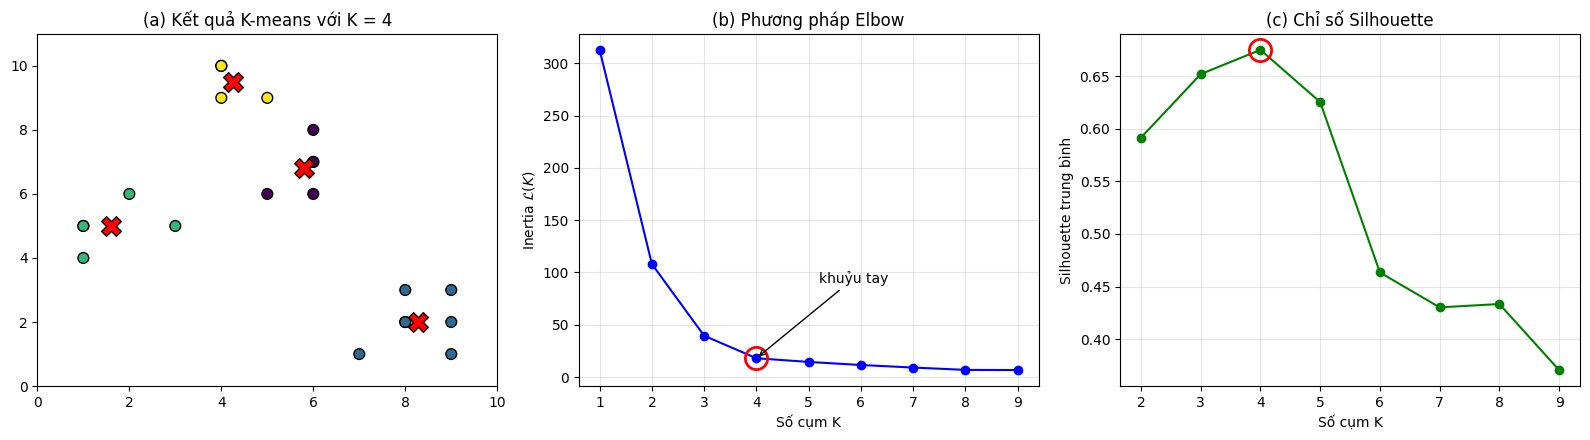

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(X[:, 0], X[:, 1], c=models[3].labels_, cmap='viridis', s=60, edgecolors='k')
axes[0].scatter(*models[3].cluster_centers_.T, marker='X', s=200, c='red', edgecolors='k')
axes[0].set_title('(a) Kết quả K-means với K = 4')
axes[0].set_xlim(0, 10); axes[0].set_ylim(0, 11)
axes[1].plot(K_values, inertias, 'bo-')
axes[1].plot(4, inertias[3], 'o', ms=16, mfc='none', mec='red', mew=2)
axes[1].annotate('khuỷu tay', (4, inertias[3]), xytext=(5.2, 90), arrowprops=dict(arrowstyle='->'))
axes[1].set_xlabel('Số cụm K'); axes[1].set_ylabel(r'Inertia $\mathcal{L}(K)$')
axes[1].set_title('(b) Phương pháp Elbow'); axes[1].grid(alpha=0.3)
axes[2].plot(range(2, 10), silhouettes, 'go-')
axes[2].plot(4, silhouettes[2], 'o', ms=16, mfc='none', mec='red', mew=2)
axes[2].set_xlabel('Số cụm K'); axes[2].set_ylabel('Silhouette trung bình')
axes[2].set_title('(c) Chỉ số Silhouette'); axes[2].grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES / 'elbow_silhouette.png', dpi=150)